In [1]:
!pip install pyfixest[jax]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.7/115.7 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 607.2/607.2 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.6 MB/s eta 0:00:00


In [2]:
!pip install linearmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 kB 2.1 MB/s eta 0:00:00


In [3]:
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from pyfixest.estimation import feols
import scipy.stats
import numpy as np
from matplotlib.lines import Line2D
import linearmodels as lm



from google.colab import drive
drive.mount('/content/gdrive')

attendance_df = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA All Game Attendance - All Game Attendance.csv')

Mounted at /content/gdrive


In [4]:
attendance_df.head()

,Unnamed: 0,Year,Day of Week,Month,Day,Time (ET),Game Type,Home Team,Away Team,Arena,City,State,Attendance
0,1,1997,Saturday,June,21,4:00 PM,Regular season,Los Angeles Sparks,New York Liberty,Great Western Forum,Los Angeles,CA,14284
1,2,1997,Saturday,June,21,7:00 PM,Regular season,Cleveland Rockers,Houston Comets,Quicken Loans Arena,Cleveland,OH,11455
2,3,1997,Saturday,June,21,5:00 AM,Regular season,Utah Starzz,Sacramento Monarchs,EnergySolutions Arena,Salt Lake City,UT,8915
3,4,1997,Sunday,June,22,4:00 PM,Regular season,Phoenix Mercury,Charlotte Sting,US Airways Center,Phoenix,AZ,16102
4,5,1997,Monday,June,23,3:00 AM,Regular season,Utah Starzz,Los Angeles Sparks,EnergySolutions Arena,Salt Lake City,UT,8036


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0063
Estimator:                   PanelOLS   R-squared (Between):             -0.0017
No. Observations:                6214   R-squared (Within):              -0.0015
Date:                Wed, Apr 09 2025   R-squared (Overall):             -0.0027
Time:                        06:46:56   Log-likelihood                -5.787e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      12.954
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(3,6156)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             13.201
                            

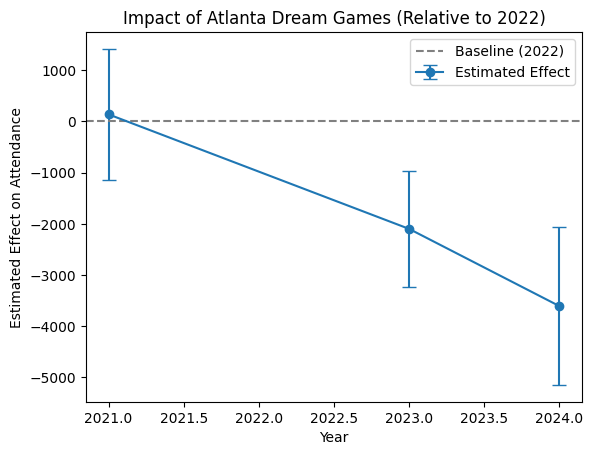

In [5]:
# Atlanta Dream (Rhyne Howard)
atl_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for New York Liberty Games (2021-2024)
atl_attendance_df['ATL_Dream_Game'] = (atl_attendance_df['Home Team'] == 'Atlanta Dream') & (atl_attendance_df['Year'].between(2021, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2022 as the Reference)
for year in [2021, 2023, 2024]:
    col_name = f'INX{year}'
    atl_attendance_df[col_name] = atl_attendance_df['ATL_Dream_Game'].astype(int)
    atl_attendance_df.loc[atl_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
atl_attendance_df = atl_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2021 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2022]',
    atl_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2021, 2023, 2024]  # Excluding 2022 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2022)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Atlanta Dream Games (Relative to 2022)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0054
Estimator:                   PanelOLS   R-squared (Between):             -0.0015
No. Observations:                6214   R-squared (Within):              -0.0012
Date:                Wed, Apr 09 2025   R-squared (Overall):             -0.0024
Time:                        06:46:57   Log-likelihood                -5.787e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      16.648
Entities:                          29   P-value                           0.0000
Avg Obs:                       214.28   Distribution:                  F(2,6157)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             14.681
                            

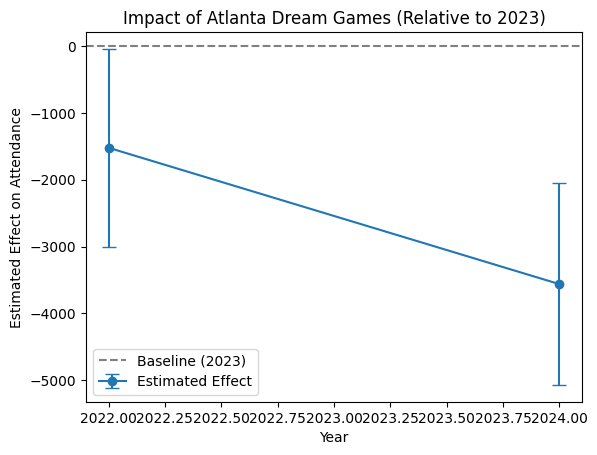

In [6]:
# Atlanta Dream (Allisha Gray)
atl_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for New York Liberty Games (2022-2024)
atl_attendance_df['ATL_Dream_Game'] = (atl_attendance_df['Home Team'] == 'Atlanta Dream') & (atl_attendance_df['Year'].between(2022, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2023 as the Reference)
for year in [2022, 2023, 2024]:
    col_name = f'INX{year}'
    atl_attendance_df[col_name] = atl_attendance_df['ATL_Dream_Game'].astype(int)
    atl_attendance_df.loc[atl_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
atl_attendance_df = atl_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2022 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2023]',
    atl_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2022, 2024]  # Excluding 2023 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2023)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of Atlanta Dream Games (Relative to 2023)")
plt.legend()
plt.show()
